# Forest disturbance near Mbandaka, DRC, with xarray

**Author:** Kisife F Jude  
**Data:** Hansen/UMD Global Forest Change v1.12, 30 m  
**Analysis window:** 18.0–18.5°E, 0.0–0.5°N

This notebook aligns the public `lossyear` and `datamask` layers, constructs an
xarray Dataset, calculates latitude-aware mapped disturbance area, and summarises
annual patterns for 2001–2024. No Google Earth Engine account is required.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

## 1. Read aligned remote raster windows

The loader uses rasterio windowed reads and returns an xarray Dataset. The cached
subset is small; the full global tiles are not downloaded. `loss_year` encodes
zero as no mapped loss and 1–24 as 2001–2024. `data_mask` separates land, water,
and no-data.

In [2]:
from congo_forest.disturbance import load_disturbance_subset, annual_disturbance

ds = load_disturbance_subset()
ds

<xarray.Dataset> Size: 8MB
Dimensions:    (y: 2000, x: 2000)
Coordinates:
  * y          (y) float64 16kB 0.4999 0.4996 0.4994 ... 0.000375 0.000125
  * x          (x) float64 16kB 18.0 18.0 18.0 18.0 18.0 ... 18.5 18.5 18.5 18.5
Data variables:
    loss_year  (y, x) int8 4MB ...
    data_mask  (y, x) int8 4MB ...
Attributes:
    title:        Mbandaka DRC forest disturbance window
    gfc_version:  GFC-2024-v1.12
    bounds_wsen:  [18.   0.  18.5  0.5]
    tile:         10N_010E

## 2. Annual mapped disturbance area

Each loss pixel is counted only in its mapped year of first stand-replacement
loss. Spherical pixel areas account for the geographic grid. Values are
**pixel-based descriptive estimates**, not design-based estimates with
confidence intervals.

In [3]:
annual = annual_disturbance(ds)
annual.round(3)

,year,mapped_disturbance_km2,rolling_3yr_mean_km2
0,2001,0.259,NaN
1,2002,2.552,1.126
2,2003,0.568,1.238
3,2004,0.594,1.840
4,2005,4.358,2.919
5,2006,3.805,3.385
6,2007,1.994,2.849
7,2008,2.747,2.600
8,2009,3.059,4.748
9,2010,8.438,6.539


In [4]:
total = annual.mapped_disturbance_km2.sum()
peak = annual.loc[annual.mapped_disturbance_km2.idxmax()]
print(f"Cumulative mapped disturbance, 2001–2024: {total:,.2f} km²")
print(f"Peak mapped year: {int(peak.year)} ({peak.mapped_disturbance_km2:,.2f} km²)")

Cumulative mapped disturbance, 2001–2024: 146.56 km²
Peak mapped year: 2024 (26.84 km²)


## 3. Spatial pattern and annual series

The rolling mean is a visual smoother, not a correction for sensor or algorithm
changes. The map shows where the first mapped loss occurred; white areas include
land without mapped loss and excluded water/no-data.

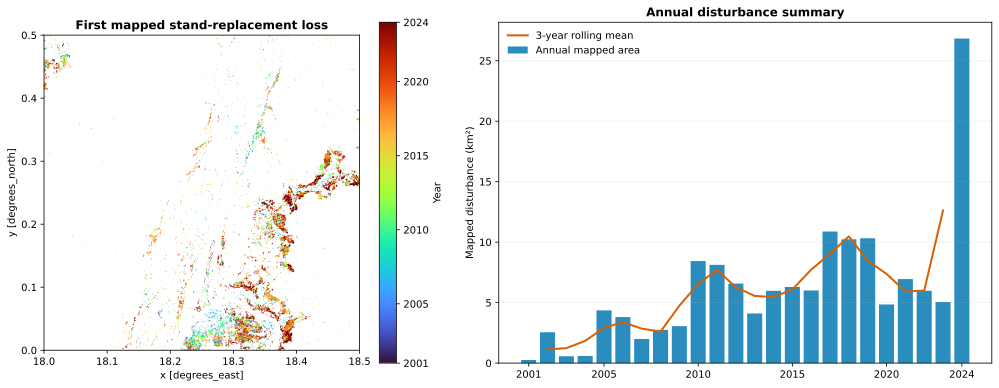

In [5]:
land = ds.data_mask == 1
loss = ds.loss_year.where((ds.loss_year > 0) & land)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
image = loss.plot.imshow(x="x", y="y", ax=axes[0], cmap="turbo", vmin=1, vmax=24,
    cbar_kwargs={"label": "Year", "ticks": [1, 5, 10, 15, 20, 24]})
cbar = image.colorbar
cbar.ax.set_yticklabels([2001, 2005, 2010, 2015, 2020, 2024])
axes[0].set_title("First mapped stand-replacement loss", fontweight="bold")
axes[0].set_aspect("equal")
axes[1].bar(annual.year, annual.mapped_disturbance_km2, color="#2b8cbe", label="Annual mapped area")
axes[1].plot(annual.year, annual.rolling_3yr_mean_km2, color="#d95f02", lw=2, label="3-year rolling mean")
axes[1].set_title("Annual disturbance summary", fontweight="bold")
axes[1].set_ylabel("Mapped disturbance (km²)")
axes[1].set_xticks([2001, 2005, 2010, 2015, 2020, 2024])
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

In [6]:
(ROOT / "outputs" / "tables").mkdir(parents=True, exist_ok=True)
annual.to_csv(ROOT / "outputs" / "tables" / "annual_disturbance_mbandaka.csv", index=False)
print("Saved outputs/tables/annual_disturbance_mbandaka.csv")

Saved outputs/tables/annual_disturbance_mbandaka.csv


## Interpretation and limitations

- This is a local case-study window, not an estimate for Mbandaka city, the DRC,
  or the entire Congo Basin.
- No tree-cover baseline is applied, so results are mapped disturbance area—not
  a percentage of year-2000 forest and not net forest change.
- The product records stand-replacement loss, not all degradation, selective
  logging, regeneration, or gain. It cannot by itself establish the cause of loss.
- Landsat sensor and algorithm changes affect temporal consistency, especially
  around the pre-/post-2011 processing transition. Definitive area estimation
  requires a suitable statistical design and uncertainty analysis.
- The three-year mean is descriptive and should not be read as a causal trend.

**Credit:** Hansen/UMD/Google/USGS/NASA.  
**Citation:** Hansen et al. (2013), *High-Resolution Global Maps of 21st-Century
Forest Cover Change*, Science 342: 850–853. Data version: GFC-2024-v1.12.